# Lesson 4: Conceptual Framework

Electrochemistry involves the interplay between numerous physical phenomenon. Attempting to learn everything up front is a fool's errand: we will first establish a broad overview of the general framework and terminology. Once established, focus will alternate between individual aspects and gradually build towards a comprehensive understanding.

Today's topics:
- Define electro**chemistry**
- Preliminary introduction of fundamental concepts and language
- Cheatsheet

**Reference:**
- Ch.1 in *Electrochemical Methods: Fundamentals and Applications*, Allen J. Bard & Larry R. Faulkner.
---

## Configure Environment

In [1]:
import sys
if '../Resources' not in sys.path:
    sys.path.append('../Resources')     # so that echem.py can be found

import numpy as np
import matplotlib.pyplot as plt

import echem                            # the shared toolkit for this course
from echem import R, T, F, f
echem.use_style()                       # course-wide graph formatting

# 1. What is electrochemistry?

Quite simply, electrochemistry is the study of chemistry that happens at electrode surfaces:
- An electrode is a surface that supplies or removes electrons
- Simplicity, flexibility and sensitivity make it a routine technique for chemists (organic, inorganic, physical, analytical, materials scientists, engineers, biologists, …)
- Complexity, flexibility and sensitivity make it a central theme in many research programs

The foundation for many energy conversion & storage technologies 
- "Electrostatic Electrochemistry at Insulators" (2008 Nature Mater., 7, 505) - using Teflon for electrochemistry!

The **chemical redox reactions** (redox = reduction/oxidation) at the electrode surface are referred to as **half-cell reactions**. These reactions can be handled in exactly the same way as any other reaction.

<div class="alert alert-block alert-success">
<b>Half-cell reaction</b>: a reaction involving an electron as a reactant or product. Electrons cannot be pulled from space, so this reaction represents only half of an overall reaction. Two halves must be combined to be a full reaction. 
</div>


Half-cell reactions are drawn as a chemical reaction between an oxidized species ( $O$ ) and a reduced species ( $R$ ):

$
\large O + ne^- \rightleftharpoons R
$

For historic reasons, **convention** is to speak from the perspective of a reduction reaction:
- thermodynamics are represented by the **standard reduction potential**, $E^0$ 
- the "forward" reaction is a reduction, which is referred to as the **cathodic reaction**
- the "reverse" reaction is an oxidation reaction, which is referred to as the **anodic reaction**
- reaction kinetics can be represented using a standard rate constant as can any chemical reaction
 - $k_f^0$ (forward) or $k_c^0$ (cathodic) represent the reduction
 - $k_r^0$ (reverse) or $k_a^0$ (anodic) represent the oxidation
 
Combining all of these concepts, we can draw a **reaction coordinate diagram** for a generic electron transfer reaction.

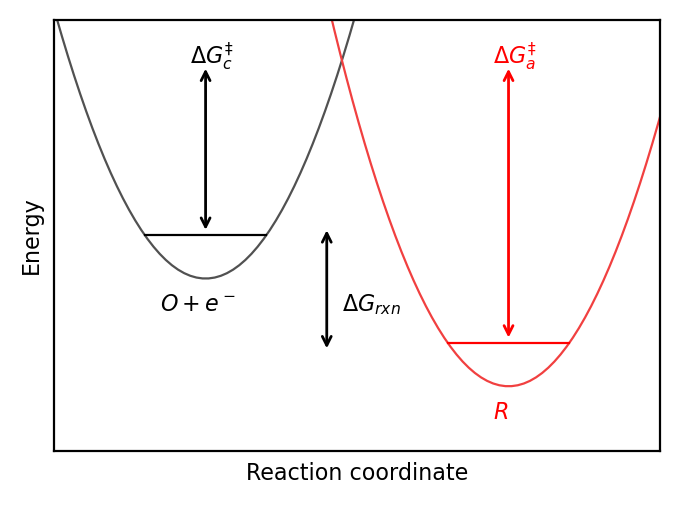

In [2]:
# Potential energy surfaces for O + e- <=> R at equilibrium
x_oxidized = np.linspace(0, 2, 100)     # reaction coordinate, oxidized well
x_reduced = np.linspace(1, 3, 100)      # reaction coordinate, reduced well

fig = plt.figure()
ax = plt.subplot(111)
ax.plot(x_oxidized, (x_oxidized - 1)**2 + 0.06)
ax.plot([0.8, 1.2], [0.1, 0.1], 'k')
ax.plot(x_reduced, (x_reduced - 2)**2 - 0.04)
ax.plot([1.8, 2.2], [0., 0.], 'r')
ax.set_ylim(-0.1, 0.3)
ax.set_xlim(0.5, 2.5)
ax.set_ylabel(r'Energy')
ax.set_xlabel('Reaction coordinate')
ax.set_xticks([])
ax.set_yticks([])

ax.annotate(r'$O + e^-$', (0.85, 0.03), fontsize=8)
ax.annotate(r'$R$', (1.95, -0.07), color="red", fontsize=8)
ax.annotate(r'$\Delta G_{rxn}$', (1.45, 0.03), fontsize=8, color='black')
ax.annotate(r'$\Delta G_{c}^\ddag$', (0.95, 0.26), fontsize=8, color='black')
ax.annotate(r'$\Delta G_{a}^\ddag$', (1.95, 0.26), fontsize=8, color='red')

for xy, xytext, c in [((1.4, 0.11), (1.4, -0.01), 'black'),
                      ((1.0, 0.10), (1.0, 0.26), 'black'),
                      ((2.0, 0.00), (2.0, 0.26), 'red')]:
    ax.annotate('', xy=xy, xycoords='data', xytext=xytext, textcoords='data',
                fontsize=8, arrowprops=dict(arrowstyle='<->', color=c))

fig.savefig('../Workspace/reactioncoordinate-conceptual.png')

Note the y-axis in the figure above. The variable $n$ is the stoichiometry for electrons involved (moles of electrons per mole of reaction) and $F$ is **Faraday's constant**, which is the amount of charge present in one mole of electrons:

$
\large F = e \cdot N_A
$

Its units are Coulombs per mole (C mol $^{-1}$ ). The basic unit of charge is a Coulomb, which is defined as the charge passed by a current (*i*) of 1 amp over a period of 1 second time (*t*). Charge ( $Q$ ) is calculated as:

$
\large Q = i \cdot t
$

The link between **energy** and voltage ( $E$ ) is described by:

$
\large \Delta G = -E \cdot Q
$

Where 1 Joule of energy is required to pass 1 Coulomb of charge through a 1 Volt potential. Using these relationships we can establish the relationship between Gibbs energy and voltage above:

$
\large \Delta G = -n \cdot F \cdot E_{rxn}
$


<div class="alert alert-block alert-danger">
<b>Check your units!</b>

(mol $_{e^-} $ mol $^{-1}$ ) $\cdot$ (C mol $_{e^-}^{-1}$ ) $\cdot$ (V) = C V mol $^{-1}$ = J mol $^{-1}$ 
</div>

# 2. Mathematics & Sign Conventions

For historical reasons the half-cell reactions are always envisioned and drawn as reductions. We know that F $_{2(g)}$ is unstable because fluorine's extreme electronegativity causes it to take electrons from other chemicals. The half-cell reaction for this reaction is:

$
\large F_{2(g)} + 2e^- \rightleftharpoons 2F^-
$ 

 $E^0$ = +2.87 V vs. NHE

The exact opposite reactivity is shown by Li $_{(s)}$ , which is unstable because it readily gives up its electron. The half-reaction is:

$
\large Li^+ + e^- \rightleftharpoons Li_{(s)}
$

 $E^0$ = -3.04 V vs. NHE




We can use the *relative* terms **oxidizing reagent** and **reducing reagent** to describe electron transfer reactions: 
- when the standard reduction potential is extremely negative, as in the lithium half reaction, the reduced phase is a very strong reducing reagent.
- when the standard reduction potential is extremely positive, as in the fluorine half reaction, the oxidized phase is a very strong oxidizing reagent.

With the energy equation established above, these two chemical reactions provide a means to remember sign conventions and terminology. The reduction of F $_2$ to F $^-$ presents a large negative $\Delta G$ , meaning it is a strongly favored reaction and F $_2$ is a strong oxidizing reagent. The exact opposite is true for lithium.

<div class="alert alert-block alert-info">
<b>Practice problem:</b>
<br>
Calculate the $E_{rxn}$ if we were to mix F $_2$ with Li $_{(s)}$ . 
<br> 
Use the markdown cell directly below to write the equation out. Then use the code cell below it to calculate the value by changing VALUE1 and VALUE2 to numbers.
</div>

$
\large E_{rxn} = E_c - E_a
$

In [3]:
# ---ACTIVITY: exchange VALUE1 and VALUE2 for appropriate numbers----
# echem.combine_half_cells(e_cathode, e_anode) returns E_cathode - E_anode.
e_rxn = echem.combine_half_cells(2.87, -3.04)

print(f'E = {e_rxn:.2f} V vs. NHE')

E = 5.91 V vs. NHE


Cathodic reactions served as the primary reactions during the early development of the field of electrochemistry (see [Lesson 6](L06-Cells-And-Electrodes.ipynb) for why). **Conventions in electrochemistry therefore tend to focus on reduction reactions**, a practice formalized by IUPAC in 1953.

If we forget the equation we can think logically. We know that F $_2$ will react with Li spontaneously. We also know that $\Delta G^0 < 0$ is required for spontaneous reactions, therefore $E_{rxn} > 0$ is expected.

Note that $E_a^0$ and $E_c^0$ do not need to be scaled by $n$ for the n-ratio between their respective reactions. When we convert from $E_{rxn}^0$ to $\Delta G^0$ , however, we do need to consider exactly which species we are calculating moles for! We can choose to either:
- set $n$ = 1 and speak of the reaction *per mole of lithium or fluorine*
- set $n$ = 2 and speak of the reaction *per mole of fluoride*

# 3. Electrochemical Potentials at Electrode Surfaces

The discussion above shows that we can describe electrochemical reactions using standard approaches in chemistry, and that we can predict spontaneous reactions from standard reduction potentials. However, a battery must be charged in order to be discharged...how does one control what happens at an electrode surface?

Chemical thermodynamics tells us that, at equilibrium:

$
\large \Delta G^0 = - R \cdot T \cdot ln(K_{eq})
$

When the system is in a non-equilibrium situation, the equilibrium constant ( $K_{eq}$ ) is replaced by the reaction quotient ( $Q$ ):

$
\large \Delta G = \Delta G^0 + R \cdot T \cdot ln(Q)
$

If $Q \neq K_{eq}$ , a chemical reaction will occur until it is.

<div class="alert alert-block alert-info">
<b>Practice problem:</b>
<br>
Adapt the chemical thermodynamics equation above such that it can be applied to electrochemical reactions.
<br> 
Hint: Gibbs energy terms must be converted to electrochemical potential terms. Write the equation in the cell below.
</div>

Adaptation of these standard equations yields the **Nernst equation**, which is possibly the most important equation that you will learn in this course:

$
\large E_{eq} = E^0 -\frac{RT}{nF}ln(Q)
$

$
\large Q = \frac{[R]}{[O]}
$

We now have a better perspective on exactly what the **standard reduction potential** ( $E^0$ ) is.

<div class="alert alert-block alert-success">
<b>Standard Reduction Potential</b>: the equilibrium electrochemical potential ( $E_{eq}$ ) for the situation where $Q = 1.0$ under standard conditions.
<br>
Take note: there is no such thing as a standard oxidation potential!
</div>



With this information, we can improve our understanding of an electrochemical potential at electrode surfaces.

The image below considers the situation for the reduction of sodium cations at a liquid mercury electrode, which yields an amalgam (sodium metal dissolved in mercury):

$ \large Na^+ + e^- \rightleftharpoons Hg(Na)
$

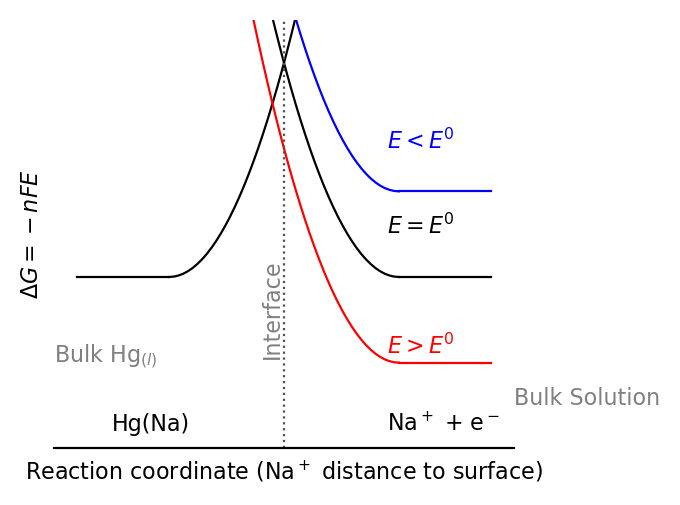

In [4]:
# How an applied potential moves the potential energy surfaces.
# Left well  = Hg(Na), the REDUCED amalgam.  Right well = Na+ + e-, the OXIDIZED ion.
x_reduced = np.linspace(1, 2, 50)
x_oxidized = np.linspace(1, 2, 50)

fig = plt.figure()
ax = plt.subplot(111)
ax.plot(x_reduced, (x_reduced - 1)**2, 'black')
ax.plot([0.6, 1.], [0., 0.], 'black')

# at E = E0: the two states are at equal energy
ax.plot(x_oxidized, (x_oxidized - 2)**2, 'black')
ax.plot([2., 2.4], [0., 0.], 'black')
ax.annotate(r'$E = E^0$', (1.95, 0.05), color="black", fontsize=8)

# at E < E0: raising the oxidized state destabilizes O, so reduction is favoured
ax.plot(x_oxidized, (x_oxidized - 2)**2 + 0.1, 'blue')
ax.plot([2., 2.4], [0.1, 0.1], 'blue')
ax.annotate(r'$E < E^0$', (1.95, 0.15), color="blue", fontsize=8)

# at E > E0: lowering the oxidized state stabilizes O, so oxidation is favoured
ax.plot(x_oxidized, (x_oxidized - 2)**2 - 0.1, 'red')
ax.plot([2., 2.4], [-0.1, -0.1], 'red')
ax.annotate(r'$E > E^0$', (1.95, -0.09), color="red", fontsize=8)

ax.vlines(1.5, -0.2, 0.3, linestyle='dotted')
ax.annotate(r'Bulk Solution', (2.5, -0.15), color="gray", fontsize=8)
ax.annotate(r'Bulk Hg$_{(l)}$', (0.5, -0.1), color="gray", fontsize=8)
ax.annotate('Interface', (1.4, -0.09), color="gray", fontsize=8, rotation=90)

ax.set_ylim(-0.2, 0.3)
ax.set_xlim(0.5, 2.5)
ax.set_ylabel(r'$\Delta G = -nFE$')
ax.set_xlabel(r'Reaction coordinate (Na$^+$ distance to surface)')
ax.set_xticks([])
ax.set_yticks([])
for side in ['right', 'left', 'top']:
    ax.spines[side].set_visible(False)

ax.annotate(r'Hg(Na)', (0.75, -0.18), color="black", fontsize=8)
ax.annotate(r'Na$^+$ + e$^-$', (1.95, -0.18), color="black", fontsize=8)

fig.savefig('../Workspace/appliedvoltage.png')

From this description, hopefully it is now obvious that we can:
1. Extract thermodynamic information by measuring the voltage at an electrode surface (or kinetic if time-dependent analysis is performed)
2. Manipulate the thermodynamics and kinetics by controlling the voltage

# 4. Reaction Rates

Remember that our generic reaction will always be that of a half reaction:

$
O + ne^- \rightleftharpoons R
$

The reversible reaction has two rate constants associated with it: $k_c$ for the (forward) reduction and $k_a$ for the (reverse) oxidation. These reactions will always be viewed as **elementary reactions** that are **first order chemical reactions**. We can once again rely upon conventional chemical equations to define reaction rate ( $\nu$ ) for each component. 

For a standard chemical reaction in a 3-dimensional solution we can define:

$
\large \nu = k_i \cdot C_i
$

<div class="alert alert-block alert-danger">
<b>Check your units!</b>
<br>
What are the units for $k_i$ ?
</div>

An electrochemical reaction, however, does not happen in a 3-dimensional solution. **It happens at a 2-dimensional slice within that solution!** We therefore need to refine the equation by removing a dimension of space from consideration. We do this by defining the concentration explicitly using distance from the electrode ( $x$ ) and time ( $t$ ): $C_i(x,t)$ . This adjustment yields a reaction rate that now has units of moles per area per unit time (for example, moles cm $^{-2}$ s $^{-1}$ ): 

$
\large \nu = k_i \cdot C_i(0, t)
$

Remember that electrochemical reactions involve the flow of electrons. We can therefore directly measure reaction rate ( $\nu$ ) as electric current ( $i$ ). Current is measured in amps (A), which does not match the reaction rate at our 2-D interface. We remedy this using Faraday's constant, the number of electrons involved in the reaction, and the area of the electrode:

$
\large k_i \cdot C_i(0, t) = \frac{i}{n \cdot F \cdot A}
$

Rearranging the equation yields the fundamental equation that guides electron transfer kinetics:

$
\large i_i = n_i F A k_i C_i(0, t)
$

<div class="alert alert-block alert-danger">
<b>Check your units!</b>
<br>
What are the units for $k_i$ ?
</div>

Note that the current was defined per species (subscript i). This is because **currents are additive**. When operating an electrochemical cell, the current measured will be the sum of all individual processes occurring at the electrode surface:

$
\large i_{total} = \sum{i_i}
$

#### Electrochemistry is the study of all processes at an electrode surface by manipulating or observing $E$ and $i_i$ .

<div class="alert alert-block alert-info">
<b>Practice problem:</b>
<br>
Use the concepts and terminology established so far to describe as much of the figure below as you can.
<br> 
Context: The figure is a cyclic voltammogram. It is performed by sweeping the electrode voltage (x-axis) in one direction, then reversing to sweep in the opposite direction. The current is measured throughout this process. Reactions at the surface are continually perturbed.
</div>

<img src="../Resources/images/SampleCV-NiOx.png" width=50%>

Notice that the anodic direction is explicitly defined on the current axis above. This is because there are two conventions regarding signs for current..and both are actively used today:
- Historic: reduction currents are given as positive values
- Modern: anodic currents are given as positive values

This can be quite confusing at first, but the electrochemical potential is ALWAYS defined such that positive is anodic. Take care when reading the literature. If it is not explicitly stated, you can usually deduce the convention being used by thinking about the direction of current flow relative to the potential applied.

Two examples from high profile journals, with research focused on similar materials:

- Cathodic currents positive

[2008 Science 321, 1075](https://www.science.org/doi/full/10.1126/science.1162018)

<img src="../Resources/images/CV2.PNG" width=30%>

- Anodic currents positive

[2013 Science 340, 60.](https://www.science.org/doi/10.1126/science.1233638)

<img src="../Resources/images/CV1.PNG" width=30%>